In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

path = '/home/alex/projects/Bosch/data/train_numeric.csv'

columns = pd.read_csv(path, nrows=0).columns

dtypes = {col: 'float32' for col in columns}
dtypes['Id'] = 'int64'
dtypes['Response'] = 'int8'

raw = pd.read_csv(path, dtype=dtypes)

print(raw.memory_usage(deep=True).sum() / 1024**3)



4.278609751723707


In [2]:
# Dataset dimensions
print(raw.shape)

# Data types
print(raw.dtypes.value_counts())

# Memory consumption in GiB
print(raw.memory_usage(deep=True).sum() / 1024**3)

(1183747, 970)
float32    968
int64        1
int8         1
Name: count, dtype: int64
4.278609751723707


In [3]:
#raw['Response'].value_counts()
raw.iloc[:, 2:12].isna().mean() * 100

L0_S0_F2     43.073816
L0_S0_F4     43.073816
L0_S0_F6     43.073816
L0_S0_F8     43.073816
L0_S0_F10    43.073816
L0_S0_F12    43.073816
L0_S0_F14    43.073816
L0_S0_F16    43.073816
L0_S0_F18    43.073816
L0_S0_F20    43.073816
dtype: float64

In [4]:
raw['L0_S0_F2'].isna().equals(raw['L0_S0_F4'].isna())

True

In [5]:
[c for c in raw.columns if 'L0_S1_' in c][:5]

['L0_S1_F24', 'L0_S1_F28']

In [6]:
raw['L0_S0_F2'].isna().equals(raw['L0_S1_F24'].isna())

False

In [7]:
raw['L0_S1_F24'].isna().mean() * 100

np.float64(43.07043650374616)

In [8]:
mask1 = raw['L0_S0_F2'].isna()
mask2 = raw['L0_S1_F24'].isna()

(mask1 != mask2).sum()

np.int64(1642)

In [9]:
pd.crosstab(mask1, mask2)

L0_S1_F24,False,True
L0_S0_F2,,
False,673061,801
True,841,509044


In [10]:
[c for c in raw.columns if c.startswith('L1_')][:10]

['L1_S24_F679',
 'L1_S24_F683',
 'L1_S24_F687',
 'L1_S24_F691',
 'L1_S24_F700',
 'L1_S24_F719',
 'L1_S24_F728',
 'L1_S24_F733',
 'L1_S24_F746',
 'L1_S24_F751']

In [11]:
raw[['L0_S0_F2', 'L1_S24_F679']].isna().mean() * 100

L0_S0_F2       43.073816
L1_S24_F679    97.984198
dtype: float64

In [12]:
pd.crosstab(
    raw['L0_S0_F2'].isna(),
    raw['L1_S24_F679'].isna()
)

L1_S24_F679,False,True
L0_S0_F2,,
False,466,673396
True,23396,486489


In [13]:
pd.crosstab(
    raw['L1_S24_F683'].isna(),
    raw['L1_S24_F679'].isna()
)

L1_S24_F679,False,True
L1_S24_F683,,
False,23862,0
True,0,1159885


In [14]:
stations = sorted({
    '_'.join(col.split('_')[:2])
    for col in raw.columns
    if col.startswith('L')
})

print(stations)
print(len(stations))

['L0_S0', 'L0_S1', 'L0_S10', 'L0_S11', 'L0_S12', 'L0_S13', 'L0_S14', 'L0_S15', 'L0_S16', 'L0_S17', 'L0_S18', 'L0_S19', 'L0_S2', 'L0_S20', 'L0_S21', 'L0_S22', 'L0_S23', 'L0_S3', 'L0_S4', 'L0_S5', 'L0_S6', 'L0_S7', 'L0_S8', 'L0_S9', 'L1_S24', 'L1_S25', 'L2_S26', 'L2_S27', 'L2_S28', 'L3_S29', 'L3_S30', 'L3_S31', 'L3_S32', 'L3_S33', 'L3_S34', 'L3_S35', 'L3_S36', 'L3_S37', 'L3_S38', 'L3_S39', 'L3_S40', 'L3_S41', 'L3_S43', 'L3_S44', 'L3_S45', 'L3_S47', 'L3_S48', 'L3_S49', 'L3_S50', 'L3_S51']
50


In [15]:
station = 'L1_S24'

cols = [c for c in raw.columns if c.startswith(station + '_')]

print(len(cols))

229


In [16]:
raw[cols].notna().any(axis=1).mean() * 100

np.float64(15.520799630326412)

In [17]:
raw[cols].count().describe()

count       229.000000
mean      40397.004367
std       38273.325921
min       11834.000000
25%       13563.000000
50%       23827.000000
75%       66484.000000
max      132922.000000
dtype: float64

In [18]:
counts = raw[cols].count()

print(counts.nsmallest(5))
print(counts.nlargest(5))

L1_S24_F907    11834
L1_S24_F920    11834
L1_S24_F925    11834
L1_S24_F930    11834
L1_S24_F935    11834
dtype: int64
L1_S24_F1829    132922
L1_S24_F1831    132922
L1_S24_F1834    132922
L1_S24_F1836    132922
L1_S24_F1838    132922
dtype: int64


In [19]:
raw['L1_S24_F907'].isna().equals(raw['L1_S24_F920'].isna())

True

In [20]:
raw[cols].notna().any(axis=1).mean() * 100

np.float64(15.520799630326412)

In [21]:
station_coverage = {}

for station in stations:
    cols = [c for c in raw.columns if c.startswith(station + '_')]
    station_coverage[station] = raw[cols].notna().any(axis=1).mean() * 100

coverage = pd.Series(station_coverage).sort_values(ascending=False)

print(coverage)

L3_S37    94.648096
L3_S30    94.598846
L3_S29    94.583471
L3_S34    94.202393
L3_S33    94.166659
L0_S1     56.929732
L0_S8     56.927789
L0_S0     56.926184
L3_S36    48.070407
L3_S35    46.640710
L0_S2     28.703262
L0_S5     28.681129
L0_S6     28.636862
L0_S7     28.358931
L0_S4     28.324887
L0_S3     28.275299
L0_S20    20.452935
L0_S13    20.449049
L0_S12    20.448711
L2_S26    19.177324
L0_S9     19.064716
L0_S11    19.045624
L0_S10    18.968580
L1_S24    15.520800
L0_S17    10.393015
L0_S15    10.259371
L0_S18    10.228621
L0_S19    10.224060
L2_S27    10.198885
L0_S14    10.190100
L0_S16    10.064566
L1_S25     7.067220
L0_S21     6.877230
L0_S22     6.808803
L0_S23     6.782699
L3_S47     5.064849
L3_S45     5.062906
L3_S48     5.062146
L3_S40     5.061386
L3_S41     5.061301
L3_S39     5.060879
L3_S51     5.056232
L3_S31     3.294876
L3_S43     2.580872
L3_S50     2.564653
L3_S44     2.517768
L3_S49     2.506701
L3_S38     2.292889
L3_S32     2.073332
L2_S28     0.809548


In [22]:
missing_pct = pd.Series({
    c: raw[c].isna().mean() * 100
    for c in raw.columns
    if c not in ['Id', 'Response']
})

print(missing_pct.describe())

print("Over 90% missing:", (missing_pct > 90).sum())
print("Over 95% missing:", (missing_pct > 95).sum())
print("Over 99% missing:", (missing_pct > 99).sum())

count    968.000000
mean      81.084898
std       30.681876
min        5.351904
25%       80.936889
50%       95.329323
75%       98.990409
max       99.894994
dtype: float64
Over 90% missing: 634
Over 95% missing: 492
Over 99% missing: 227


In [23]:
for col in ['L0_S0_F2', 'L1_S24_F679']:
    print(col)
    print(
        raw.groupby('Response')[col]
        .apply(lambda x: x.notna().mean() * 100)
    )

L0_S0_F2
Response
0    56.952351
1    52.449484
Name: L0_S0_F2, dtype: float64
L1_S24_F679
Response
0    2.016539
1    1.889810
Name: L1_S24_F679, dtype: float64


In [24]:
good = raw['Response'] == 0
bad = raw['Response'] == 1

differences = {}

for col in missing_pct.index:
    differences[col] = (
        raw.loc[bad, col].notna().mean()
        - raw.loc[good, col].notna().mean()
    ) * 100

diff = pd.Series(differences)

print(diff.abs().sort_values(ascending=False).head(20))


L3_S32_F3850    14.086446
L3_S33_F3857    13.623645
L3_S33_F3869    13.623645
L3_S33_F3859    13.623645
L3_S33_F3871    13.623645
L3_S33_F3867    13.623645
L3_S33_F3865    13.623645
L3_S33_F3863    13.623645
L3_S33_F3861    13.623645
L3_S33_F3873    13.623645
L3_S33_F3855    13.623645
L3_S34_F3876    11.144610
L3_S34_F3880    11.144610
L3_S34_F3882    11.144610
L3_S34_F3878    11.144610
L1_S24_F1571     6.136191
L1_S24_F1569     6.136191
L1_S24_F1575     6.136191
L1_S24_F1578     6.136191
L1_S24_F1573     6.136191
dtype: float64


In [25]:
print(diff.loc[diff.abs().nlargest(20).index])

L3_S32_F3850    14.086446
L3_S33_F3855   -13.623645
L3_S33_F3857   -13.623645
L3_S33_F3859   -13.623645
L3_S33_F3861   -13.623645
L3_S33_F3863   -13.623645
L3_S33_F3865   -13.623645
L3_S33_F3867   -13.623645
L3_S33_F3869   -13.623645
L3_S33_F3871   -13.623645
L3_S33_F3873   -13.623645
L3_S34_F3876   -11.144610
L3_S34_F3878   -11.144610
L3_S34_F3880   -11.144610
L3_S34_F3882   -11.144610
L1_S24_F1569     6.136191
L1_S24_F1571     6.136191
L1_S24_F1573     6.136191
L1_S24_F1575     6.136191
L1_S24_F1578     6.136191
dtype: float64


In [26]:
col = 'L3_S32_F3850'

print(raw[col].describe())
print("Missing:", raw[col].isna().mean() * 100)

count    24543.000000
mean         0.000029
std          0.045052
min         -0.798000
25%         -0.031000
50%          0.004000
75%          0.031000
max          0.166000
Name: L3_S32_F3850, dtype: float64
Missing: 97.92666845195807


In [27]:
Q1 = raw[col].quantile(0.25)
Q3 = raw[col].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (raw[col] < lower) | (raw[col] > upper)

print("Lower bound:", lower)
print("Upper bound:", upper)
print("Outliers:", outliers.sum())
print("Percentage:", outliers.sum() / raw[col].count() * 100)

Lower bound: -0.124
Upper bound: 0.124
Outliers: 105
Percentage: 0.42782055983376116


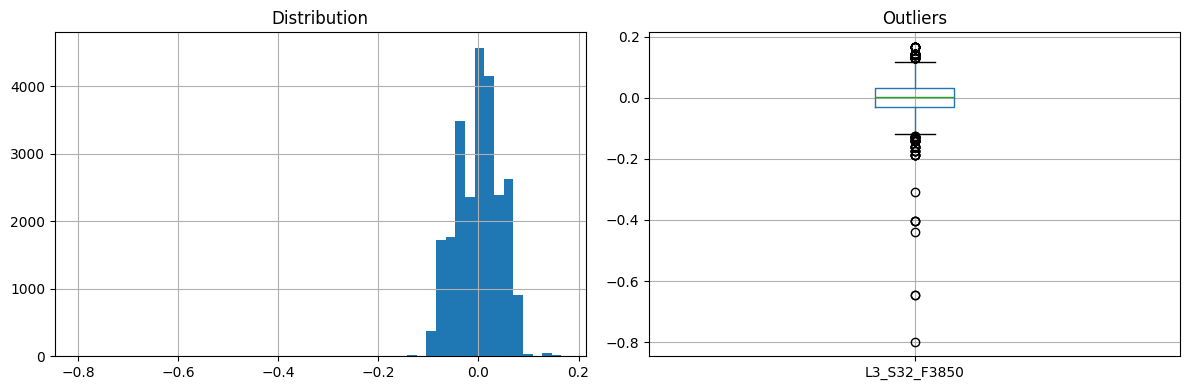

In [28]:

col = 'L3_S32_F3850'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

raw[col].hist(bins=50, ax=axes[0])
axes[0].set_title('Distribution')

raw.boxplot(column=col, ax=axes[1])
axes[1].set_title('Outliers')

plt.tight_layout()
plt.show()

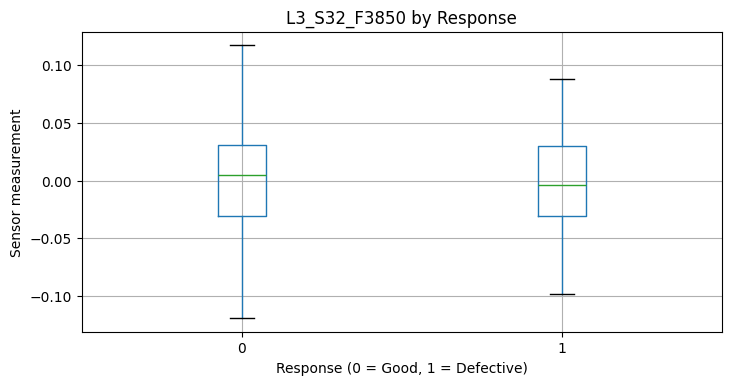

In [29]:
raw.boxplot(
    column=col,
    by='Response',
    figsize=(8, 4),
    showfliers=False
)

plt.title(f'{col} by Response')
plt.suptitle('')
plt.xlabel('Response (0 = Good, 1 = Defective)')
plt.ylabel('Sensor measurement')
plt.show()

In [30]:
valid = raw[col].notna()

table = pd.crosstab(
    outliers[valid],
    raw.loc[valid, 'Response']
)

print("Counts:")
print(table)

print("\nFailure rates (%):")
print(table.div(table.sum(axis=1), axis=0) * 100)

Counts:
Response          0     1
L3_S32_F3850             
False         23332  1106
True            105     0

Failure rates (%):
Response               0         1
L3_S32_F3850                      
False          95.474261  4.525739
True          100.000000  0.000000


In [31]:
# Count available measurements for each manufactured part
measurement_count = np.zeros(len(raw), dtype=np.uint16)

for col in missing_pct.index:
    measurement_count += raw[col].notna().to_numpy(dtype=np.uint16)

raw['measurement_count'] = measurement_count

# Compare good and defective parts
print(raw.groupby('Response')['measurement_count'].describe())

              count        mean        std  min    25%    50%    75%    max
Response                                                                   
0         1176868.0  183.103851  25.751917  0.0  161.0  190.0  204.0  327.0
1            6879.0  182.129234  26.202352  0.0  160.0  190.0  204.0  274.0


/tmp/ipykernel_1202/576790139.py:7: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  raw['measurement_count'] = measurement_count


In [32]:
bins = pd.cut(
    raw['measurement_count'],
    bins=[-1, 50, 100, 150, 200, 250, 400]
)

result = raw.groupby(bins, observed=True)['Response'].agg(['count', 'mean'])

result['failure_rate_%'] = result['mean'] * 100

print(result)

                    count      mean  failure_rate_%
measurement_count                                  
(-1, 50]             2265  0.003532        0.353201
(50, 100]             785  0.011465        1.146497
(100, 150]          66086  0.008519        0.851920
(150, 200]         803548  0.005474        0.547447
(200, 250]         309446  0.006114        0.611415
(250, 400]           1617  0.004947        0.494743


In [33]:
station_counts = {}

for station in stations:
    cols = [c for c in raw.columns if c.startswith(station + '_')]
    station_counts[f'{station}_count'] = raw[cols].count(axis=1).astype('uint16')

station_features = pd.DataFrame(station_counts)

print(station_features.shape)
print(station_features.head())

(1183747, 50)
   L0_S0_count  L0_S1_count  L0_S10_count  L0_S11_count  L0_S12_count  \
0           12            2             0            12             0   
1            0            0             0             0            12   
2           12            2            12             0             0   
3           12            2            12             0             0   
4           12            2             0            12             0   

   L0_S13_count  L0_S14_count  L0_S15_count  L0_S16_count  L0_S17_count  ...  \
0             0             0             0             0             0  ...   
1             2             9             0             2             0  ...   
2             0             0             0             0             0  ...   
3             0             0             0             0             0  ...   
4             0             0             0             0             0  ...   

   L3_S40_count  L3_S41_count  L3_S43_count  L3_S44_count  L3_S45_

In [34]:
pd.crosstab(
    station_features['L1_S24_count'] > 0,
    raw['Response'],
    normalize='index'
) * 100

Response,0,1
L1_S24_count,,
False,99.464211,0.535789
True,99.172141,0.827859


In [35]:
results = []

for station in stations:
    present = station_features[f'{station}_count'] > 0

    rate_present = raw.loc[present, 'Response'].mean() * 100
    rate_absent = raw.loc[~present, 'Response'].mean() * 100

    results.append([
        station,
        rate_present,
        rate_absent,
        rate_present - rate_absent
    ])

station_rates = pd.DataFrame(
    results,
    columns=['Station', 'Present_%', 'Absent_%', 'Difference_pp']
)

print(
    station_rates.reindex(
        station_rates['Difference_pp'].abs().sort_values(ascending=False).index
    ).head(15).round(3)
)

   Station  Present_%  Absent_%  Difference_pp
32  L3_S32      4.506     0.498          4.008
33  L3_S33      0.498     1.930         -1.433
34  L3_S34      0.513     1.692         -1.179
31  L3_S31      0.272     0.592         -0.320
24  L1_S24      0.828     0.536          0.292
26  L2_S26      0.747     0.542          0.205
38  L3_S38      0.781     0.576          0.205
28  L2_S28      0.699     0.580          0.119
27  L2_S27      0.681     0.570          0.111
1    L0_S1      0.535     0.642         -0.107
22   L0_S8      0.535     0.642         -0.107
0    L0_S0      0.535     0.642         -0.106
43  L3_S44      0.490     0.583         -0.094
49  L3_S51      0.505     0.585         -0.081
25  L1_S25      0.507     0.587         -0.080


In [36]:
s32 = station_features['L3_S32_count'] > 0
s33 = station_features['L3_S33_count'] > 0

table = pd.crosstab(
    [s32, s33],
    raw['Response']
)

print("Counts:")
print(table)

print("\nFailure rates (%):")
print(table[1] / table.sum(axis=1) * 100)

Counts:
Response                         0     1
L3_S32_count L3_S33_count               
False        False           62166   319
             True          1091265  5454
True         False            5553  1014
             True            17884    92

Failure rates (%):
L3_S32_count  L3_S33_count
False         False            0.510523
              True             0.497301
True          False           15.440841
              True             0.511794
dtype: float64


In [37]:
station_features['S32_only'] = (
    s32 & ~s33
).astype('uint8')

print(station_features['S32_only'].value_counts())

S32_only
0    1177180
1       6567
Name: count, dtype: int64


In [38]:
from sklearn.model_selection import train_test_split

X = station_features
y = raw['Response']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

print("Training failure rate:", y_train.mean() * 100)
print("Testing failure rate:", y_test.mean() * 100)

Training: (946997, 51)
Testing: (236750, 51)
Training failure rate: 0.5811000457234817
Testing failure rate: 0.5812038014783527


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

# Exclude S32_only for now because we selected it using
# information from the entire dataset
features = X_train.columns.drop('S32_only')

model = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=200,
    class_weight='balanced',
    random_state=42
)

model.fit(X_train[features], y_train)

y_pred = model.predict(X_test[features])
y_prob = model.predict_proba(X_test[features])[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, zero_division=0))
print("Average precision:", average_precision_score(y_test, y_prob))

[[145544  89830]
 [   604    772]]
              precision    recall  f1-score   support

           0       1.00      0.62      0.76    235374
           1       0.01      0.56      0.02      1376

    accuracy                           0.62    236750
   macro avg       0.50      0.59      0.39    236750
weighted avg       0.99      0.62      0.76    236750

Average precision: 0.04277670342604918


In [40]:
from sklearn.base import clone
from sklearn.metrics import precision_score, recall_score

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train[features], y_train,
    test_size=0.2,
    stratify=y_train,
    random_state=42
)

val_model = clone(model)
val_model.fit(X_fit, y_fit)

probs = val_model.predict_proba(X_val)[:, 1]

for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (probs >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_val, pred, zero_division=0):.3f} | "
        f"Recall: {recall_score(y_val, pred, zero_division=0):.3f} | "
        f"Flagged: {pred.sum()}"
    )

Threshold: 0.5 | Precision: 0.009 | Recall: 0.589 | Flagged: 70646
Threshold: 0.6 | Precision: 0.113 | Recall: 0.154 | Flagged: 1503
Threshold: 0.7 | Precision: 0.125 | Recall: 0.153 | Flagged: 1350
Threshold: 0.8 | Precision: 0.175 | Recall: 0.148 | Flagged: 930
Threshold: 0.9 | Precision: 0.175 | Recall: 0.148 | Flagged: 930


In [41]:
from sklearn.metrics import confusion_matrix, classification_report

# Retrain using all training data
final_model = clone(model)
final_model.fit(X_train[features], y_train)

# Predict probabilities
test_probs = final_model.predict_proba(X_test[features])[:, 1]

# Apply selected threshold
test_pred = (test_probs >= 0.8).astype(int)

print(confusion_matrix(y_test, test_pred))
print(classification_report(y_test, test_pred, zero_division=0))
print("Average precision:", average_precision_score(y_test, test_probs))

[[234320   1054]
 [  1178    198]]
              precision    recall  f1-score   support

           0       0.99      1.00      1.00    235374
           1       0.16      0.14      0.15      1376

    accuracy                           0.99    236750
   macro avg       0.58      0.57      0.57    236750
weighted avg       0.99      0.99      0.99    236750

Average precision: 0.04277670342604918


In [42]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score

hgb = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42
)

hgb.fit(X_fit, y_fit)

val_probs = hgb.predict_proba(X_val)[:, 1]

print("Average precision:",
      average_precision_score(y_val, val_probs))

Average precision: 0.05096174692884877


In [43]:
tree_probs = val_model.predict_proba(X_val)[:, 1]

print("Baseline:", y_val.mean())
print("Decision Tree AP:",
      average_precision_score(y_val, tree_probs))
print("HistGradientBoosting AP:",
      average_precision_score(y_val, val_probs))

Baseline: 0.005813093980992608
Decision Tree AP: 0.04227725703385202
HistGradientBoosting AP: 0.05096174692884877


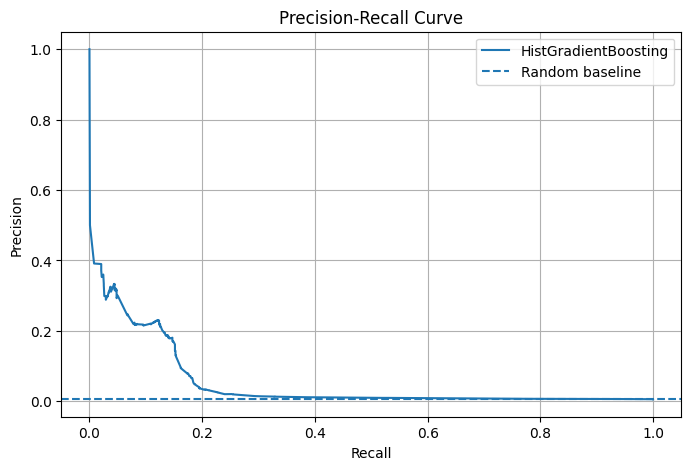

In [44]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_val, val_probs
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision, label='HistGradientBoosting')
plt.axhline(y_val.mean(), linestyle='--', label='Random baseline')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)
plt.show()

In [45]:
sensor_cols = [c for c in raw.columns if c.startswith('L')]

coverage = pd.Series({
    c: raw.loc[X_fit.index, c].notna().mean()
    for c in sensor_cols
})

selected = coverage.nlargest(20).index.tolist()

print(selected)

['L3_S37_F3944', 'L3_S37_F3946', 'L3_S37_F3948', 'L3_S37_F3950', 'L3_S30_F3724', 'L3_S30_F3729', 'L3_S30_F3734', 'L3_S30_F3739', 'L3_S30_F3764', 'L3_S30_F3769', 'L3_S30_F3774', 'L3_S30_F3779', 'L3_S30_F3784', 'L3_S30_F3789', 'L3_S30_F3794', 'L3_S30_F3799', 'L3_S30_F3804', 'L3_S30_F3809', 'L3_S30_F3814', 'L3_S30_F3819']


In [46]:
X_fit_new = pd.concat([
    X_fit,
    raw.loc[X_fit.index, selected]
], axis=1)

X_val_new = pd.concat([
    X_val,
    raw.loc[X_val.index, selected]
], axis=1)

In [47]:
hgb_new = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    class_weight='balanced',
    random_state=42
)

hgb_new.fit(X_fit_new, y_fit)

new_probs = hgb_new.predict_proba(X_val_new)[:, 1]

print("Original AP:", average_precision_score(y_val, val_probs))
print("With sensors AP:", average_precision_score(y_val, new_probs))

Original AP: 0.05096174692884877
With sensors AP: 0.04951003848818854


In [48]:
focus_stations = ['L3_S32', 'L3_S33', 'L3_S34', 'L1_S24']

selected_focus = []

for station in focus_stations:
    cols = [c for c in sensor_cols if c.startswith(station + '_')]

    coverage = raw.loc[X_fit.index, cols].notna().mean()
    selected_focus.extend(coverage.nlargest(5).index.tolist())

print(selected_focus)

['L3_S32_F3850', 'L3_S33_F3855', 'L3_S33_F3857', 'L3_S33_F3859', 'L3_S33_F3861', 'L3_S33_F3863', 'L3_S34_F3876', 'L3_S34_F3878', 'L3_S34_F3880', 'L3_S34_F3882', 'L1_S24_F1829', 'L1_S24_F1831', 'L1_S24_F1834', 'L1_S24_F1836', 'L1_S24_F1838']


In [49]:
from sklearn.base import clone

X_fit_focus = pd.concat([
    X_fit, raw.loc[X_fit.index, selected_focus]
], axis=1)

X_val_focus = pd.concat([
    X_val, raw.loc[X_val.index, selected_focus]
], axis=1)

hgb_focus = clone(hgb)
hgb_focus.fit(X_fit_focus, y_fit)

focus_probs = hgb_focus.predict_proba(X_val_focus)[:, 1]

print("Station only:", average_precision_score(y_val, val_probs))
print("Highest coverage:", average_precision_score(y_val, new_probs))
print("Selected stations:", average_precision_score(y_val, focus_probs))

Station only: 0.05096174692884877
Highest coverage: 0.04951003848818854
Selected stations: 0.054228481917728305


In [50]:
X_fit_presence = X_fit.join(
    raw.loc[X_fit.index, selected_focus]
    .notna().astype('uint8')
    .add_suffix('_present')
)

X_val_presence = X_val.join(
    raw.loc[X_val.index, selected_focus]
    .notna().astype('uint8')
    .add_suffix('_present')
)

hgb_presence = clone(hgb)
hgb_presence.fit(X_fit_presence, y_fit)

presence_probs = hgb_presence.predict_proba(X_val_presence)[:, 1]

print("Station only:", average_precision_score(y_val, val_probs))
print("Sensor presence:", average_precision_score(y_val, presence_probs))
print("Sensor values:", average_precision_score(y_val, focus_probs))

Station only: 0.05096174692884877
Sensor presence: 0.05069991769228973
Sensor values: 0.054228481917728305


In [51]:
train_differences = {}

for station in stations:
    present = X_fit[f'{station}_count'] > 0

    if present.any() and (~present).any():
        train_differences[station] = (
            y_fit[present].mean() -
            y_fit[~present].mean()
        ) * 100

train_ranking = pd.Series(train_differences)

print(train_ranking.abs().nlargest(10))

L3_S32    4.066101
L3_S33    1.449103
L3_S34    1.179111
L3_S31    0.327206
L1_S24    0.315445
L2_S26    0.229527
L2_S28    0.180221
L3_S38    0.176370
L0_S1     0.121717
L0_S0     0.121668
dtype: float64


In [52]:
best_ap = 0
best_params = None
best_model = None

for leaves in [7, 15, 31]:
    for lr in [0.05, 0.1]:

        candidate = HistGradientBoostingClassifier(
            max_iter=100,
            max_leaf_nodes=leaves,
            learning_rate=lr,
            class_weight='balanced',
            random_state=42
        )

        candidate.fit(X_fit_focus, y_fit)

        probs = candidate.predict_proba(X_val_focus)[:, 1]
        ap = average_precision_score(y_val, probs)

        print(f"Leaves={leaves}, LR={lr}: AP={ap:.4f}")

        if ap > best_ap:
            best_ap = ap
            best_params = (leaves, lr)
            best_model = candidate

print("\nBest AP:", best_ap)
print("Best parameters:", best_params)

Leaves=7, LR=0.05: AP=0.0525
Leaves=7, LR=0.1: AP=0.0523
Leaves=15, LR=0.05: AP=0.0506
Leaves=15, LR=0.1: AP=0.0542
Leaves=31, LR=0.05: AP=0.0477
Leaves=31, LR=0.1: AP=0.0514

Best AP: 0.054228481917728305
Best parameters: (15, 0.1)


In [53]:
from sklearn.metrics import precision_score, recall_score

probs = best_model.predict_proba(X_val_focus)[:, 1]

# Flag the highest-risk 1% of parts
k = int(len(probs) * 0.01)

top_indices = np.argsort(probs)[-k:]

pred = np.zeros(len(probs), dtype=int)
pred[top_indices] = 1

print("Parts flagged:", pred.sum())
print("Defects detected:", y_val.iloc[top_indices].sum())
print("Precision:", precision_score(y_val, pred))
print("Recall:", recall_score(y_val, pred))

Parts flagged: 1894
Defects detected: 183
Precision: 0.0966209081309398
Recall: 0.16621253405994552


In [54]:
ranked = np.argsort(probs)[::-1]
y_true = y_val.to_numpy()

for pct in [0.5, 1, 2, 5, 10]:
    k = int(len(probs) * pct / 100)

    detected = y_true[ranked[:k]].sum()

    precision = detected / k * 100
    recall = detected / y_true.sum() * 100

    print(
        f"Inspect {pct}% | "
        f"Precision: {precision:.2f}% | "
        f"Recall: {recall:.2f}%"
    )

Inspect 0.5% | Precision: 17.11% | Recall: 14.71%
Inspect 1% | Precision: 9.66% | Recall: 16.62%
Inspect 2% | Precision: 5.20% | Recall: 17.89%
Inspect 5% | Precision: 2.83% | Recall: 24.34%
Inspect 10% | Precision: 1.82% | Recall: 31.34%


In [55]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score

# Prepare final features
X_train_final = X_train[features].join(
    raw.loc[X_train.index, selected_focus]
)

X_test_final = X_test[features].join(
    raw.loc[X_test.index, selected_focus]
)

# Train on all training data
final_model = clone(best_model)
final_model.fit(X_train_final, y_train)

# Evaluate
test_probs = final_model.predict_proba(X_test_final)[:, 1]

print("Test AP:", average_precision_score(y_test, test_probs))

# Inspect highest-risk 1%
k = int(len(test_probs) * 0.01)
top_idx = np.argsort(test_probs)[-k:]

detected = y_test.to_numpy()[top_idx].sum()

print("Parts inspected:", k)
print("Defects detected:", detected)
print("Precision:", detected / k)
print("Recall:", detected / y_test.sum())

Test AP: 0.04347394147836184
Parts inspected: 2367
Defects detected: 208
Precision: 0.08787494719053654
Recall: 0.1511627906976744
